# Atmospheric effects in DORIS positioning

In [1]:
from pathlib import Path
from datetime import datetime, timedelta
import tempfile
import math

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from dsoclasses.troposphere.vmf3 import SiteVmf3
from dsoclasses.troposphere.gpt3 import saastamoinen_zhd
from dsoclasses.time.pyattotime import to_attoseconds, at2pt

# Keep the example easy to run. Switch to True for the real DORIS experiment.
SITE = 'DIOB'  # DORIS beacon at Dionysos, Greece

# Original file names from the uploaded notebook.
DATA_DIR = Path('../../data')
DORIS_RINEX = DATA_DIR / 's6arx24001.001'
DPOD_SINEX = DATA_DIR / 'dpod2020_041.snx'
SENTINEL6_SP3 = DATA_DIR / 'ssas6a20.b23357.e24001.DG_.sp3.001'
DORIS_VMF3 = DATA_DIR / 'y2024.vmf3_d'  # Note: '_d', not GNSS '_g'

# These offsets must be established from the file headers (and leap seconds).
# The numbers are ADDED to the RINEX epoch to get the target time scale.
# Keep them None until you have verified the RINEX and SP3 time systems.
RINEX_TO_SP3_SECONDS = 0
RINEX_TO_VMF_UTC_SECONDS = 0

# Avoid processing an entire day for a simple figure.
MAX_REAL_OBSERVATIONS = 450
MIN_ELEVATION_DEG = 5.0
C_LIGHT = 299_792_458.0  # speed of light [m/s]

## 1. What is tropospheric delay?

A DORIS beacon transmits radio signals **upwards**, through the electrically neutral atmosphere, to the satellite. Refraction increases the effective signal path length. The delay is commonly written in **metres of equivalent path length**, not in seconds.

The neutral-atmosphere (often called *tropospheric*) delay at elevation angle $e$ is approximated by

$$
\boxed{T(e,t) = ZHD(t)\,m_h(e,t) + ZWD(t)\,m_w(e,t)}
$$

- **ZHD**: zenith hydrostatic delay, mainly associated with the mass of air above the station; typically around 2 m.
- **ZWD**: zenith wet delay, caused by water vapour; smaller, more variable, and harder to predict.
- **$m_h,m_w$**: dimensionless hydrostatic and wet mapping functions; both are close to 1 at $90^\circ$ elevation and grow toward the horizon.

**Important:** The delay is almost non-dispersive at DORIS radio frequencies. It does *not* disappear when combining the two transmitted DORIS frequencies to remove the dominant ionospheric effect.

## 2. Prepare a station, epochs, and VMF3 data

The real-data path uses the original DORIS RINEX observation file, DPOD SINEX station coordinates, precise SP3 orbit, and **site-wise DORIS VMF3** product. The VMF3 file contains six-hourly coefficients and zenith delays, which `SiteVmf3` interpolates to observation epochs.

In [2]:
def shift_epoch(epoch, seconds):
    """Shift an epoch without converting an absolute timestamp to a float.

    Python datetime and attotime.attodatetime accept different timedelta
    classes; the central time library preserves sub-microsecond labels.
    """
    if seconds == 0:
        return epoch
    if isinstance(epoch, datetime):
        return epoch + timedelta(seconds=seconds)
    import attotime  # needed only when using real DORIS RINEX epochs
    return epoch + attotime.attotimedelta(seconds=seconds)


from dsoclasses.rinex.doris.rinex import DorisRinex
from dsoclasses.sinex.sinex import extract_sinex_coordinates
from dsoclasses.orbits.interpolator import Sp3Interpolator
from dsoclasses.geodesy.transformations import car2ell, azele
from dsoclasses.doris.algorithms import beacon_nominal_frequency

rnx = DorisRinex(str(DORIS_RINEX))
intrp = Sp3Interpolator.from_sp3(
    str(SENTINEL6_SP3), ['L'], interval_in_sec=310,
    min_data_pts=8, stencil_pts=8, itype='Barycentric'
)
if len(intrp.satellites) != 1:
    raise ValueError(f'Expected a single Sentinel-6A SP3 satellite: {intrp.satellites}')
sat_id = intrp.satellites[0]
print('RINEX time system:', rnx.time_sys, '| SP3 time system:', intrp.time_system())
if RINEX_TO_SP3_SECONDS is None or RINEX_TO_VMF_UTC_SECONDS is None:
    raise ValueError(
        'Set RINEX_TO_SP3_SECONDS and RINEX_TO_VMF_UTC_SECONDS '
        'after inspecting the RINEX / SP3 time systems.'
    )

solution = extract_sinex_coordinates(
    str(DPOD_SINEX), [SITE], rnx.time_first_obs, True
)[SITE]
station_xyz = np.array([solution[k] for k in ('X', 'Y', 'Z')], dtype=float)
latitude, longitude, height_m = car2ell(*station_xyz)
beacon_id = rnx.name2id(SITE)
beacon_frequency_hz = beacon_nominal_frequency(rnx.kfactor(SITE))[0]
epoch = at2pt(rnx.time_first_obs)
vmf_file = DORIS_VMF3

# Select valid observations of the DIOB beacon; collect pressure if P
# is available. The RINEX reader does not guarantee P at every epoch.
times = []
elevations_rad = []
pressures_hpa = []
skipped = 0
for block in rnx:
    for beacon, obs in block:
        if beacon != beacon_id:
            continue
        try:
            t_rnx = block.t()
            t_sp3 = shift_epoch(t_rnx, RINEX_TO_SP3_SECONDS)
            sat_xyz = np.asarray(intrp.sat_at(sat_id, t_sp3)[:3], float)
            _, _, el = azele(sat_xyz, station_xyz)
            if not np.isfinite(el) or np.degrees(el) < MIN_ELEVATION_DEG:
                continue
            pressure = float(obs.get('P', {}).get('value', np.nan))
            if not (np.isnan(pressure) or 300. < pressure < 1100.):
                raise ValueError('Invalid DORIS pressure [hPa]')
            t_vmf = shift_epoch(t_rnx, RINEX_TO_VMF_UTC_SECONDS)
            times.append(at2pt(t_vmf))  # display and VMF epoch in UTC
            elevations_rad.append(el)
            pressures_hpa.append(pressure)
        except (ValueError, LookupError, KeyError, TypeError):
            skipped += 1
        if len(times) >= MAX_REAL_OBSERVATIONS:
            break
    if len(times) >= MAX_REAL_OBSERVATIONS:
        break
if len(times) < 2:
    raise RuntimeError('Fewer than two usable DIOB observations; check epochs, orbit and RINEX.')
elevations_rad = np.asarray(elevations_rad, dtype=float)
pressures_hpa = np.asarray(pressures_hpa, dtype=float)
print(f'Using {len(times)} real RINEX observations; skipped {skipped} unusable records.')

# Select ONLY this site's VMF3 data. Pass a list, not a site-name string.
vmf = SiteVmf3(str(vmf_file), site_list=[SITE])
print(f'Site: {SITE}; number of epochs: {len(times)}')
print(f'Latitude: {np.degrees(latitude):.3f}°, longitude: {np.degrees(longitude):.3f}°, '
      f'height: {height_m:.1f} m')

RINEX time system: DOR | SP3 time system: TAI
Using 450 real RINEX observations; skipped 0 unusable records.
Site: DIOB; number of epochs: 450
Latitude: 38.078°, longitude: 23.933°, height: 513.3 m


/tmp/ipykernel_3405243/819244756.py:83: RuntimeWarning: Skipped 2 VMF3 record(s) with nonpositive wet mapping coefficient a_w in ../../data/y2024.vmf3_d; first: DIOB at 2024-02-12 06:00:00 (line 37832, a_w=-2.62e-06). Interpolation across missing six-hour records is not permitted.
  vmf = SiteVmf3(str(vmf_file), site_list=[SITE])


## 3. Hydrostatic (dry) zenith delay from pressure

The standard Saastamoinen/Davis approximation is

$$
ZHD = \frac{0.0022768\,p}{1-0.00266\cos(2\varphi)-0.00000028\,h},
$$

where $p$ is **surface pressure in hPa**, $\varphi$ is geodetic latitude in **radians**, and $h$ is station height in **metres**. This corrects a mistake in the uploaded notebook: the denominator **must not be omitted**.

DORIS RINEX can contain meteorological observations (`P`). `saastamoinen_zhd()` gives the pressure-derived hydrostatic component. VMF3 independently provides an atmospheric-model ZHD; the two values need not agree exactly.

Example at the first available epoch:
  Pressure:        958.40 hPa
  ZHD from P:      2.1838 m
  ZHD from VMF3:   2.1958 m
  ZWD from VMF3:   0.1097 m


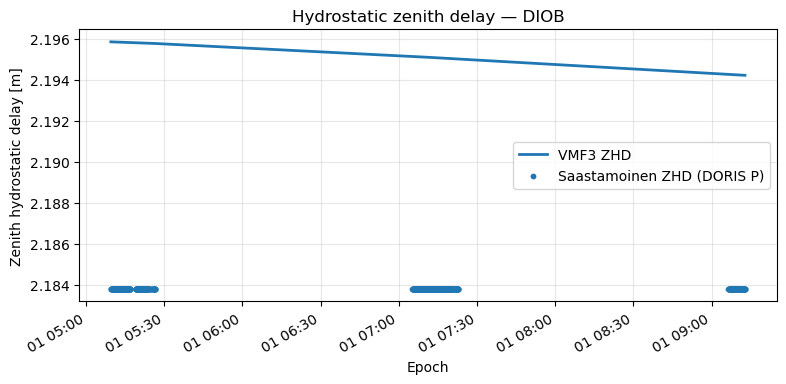

In [5]:
# Compute VMF3 values and pressure-based hydrostatic delays for all times.
# A VMF3 record also supplies a priori ZWD and mapping coefficients.
vmf_info = [vmf.vmf3(SITE, latitude, longitude, float(el), t)
            for t, el in zip(times, elevations_rad)]
vmf_zhd = np.array([v['zhd'] for v in vmf_info], dtype=float)
vmf_zwd = np.array([v['zwd'] for v in vmf_info], dtype=float)

# Missing RINEX pressure values yield NaN and are omitted from the plot.
pressure_zhd = np.array([
    saastamoinen_zhd(latitude, height_m, p) if np.isfinite(p) else np.nan
    for p in pressures_hpa
])

print('Example at the first available epoch:')
print(f'  Pressure:        {pressures_hpa[0]:.2f} hPa')
print(f'  ZHD from P:      {pressure_zhd[0]:.4f} m')
print(f'  ZHD from VMF3:   {vmf_zhd[0]:.4f} m')
print(f'  ZWD from VMF3:   {vmf_zwd[0]:.4f} m')

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(times, vmf_zhd, label='VMF3 ZHD', lw=2)
if np.any(np.isfinite(pressure_zhd)):
    ax.scatter(times, pressure_zhd, label='Saastamoinen ZHD (DORIS P)', s=10)
ax.set(xlabel='Epoch', ylabel='Zenith hydrostatic delay [m]',
       title='Hydrostatic zenith delay — ' + 'DIOB')
ax.grid(alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.show()

## 4. Wet zenith delay

The **wet** component depends on water vapour along the entire path and varies more rapidly than the hydrostatic component. A surface humidity observation alone is usually not sufficient to determine it accurately.

Here, `SiteVmf3` returns an **a priori model ZWD**, not a ZWD estimated from DORIS observations. Later, in positioning, we may estimate an additional $\Delta ZWD$ (or other atmospheric parameters) from the tracking data.

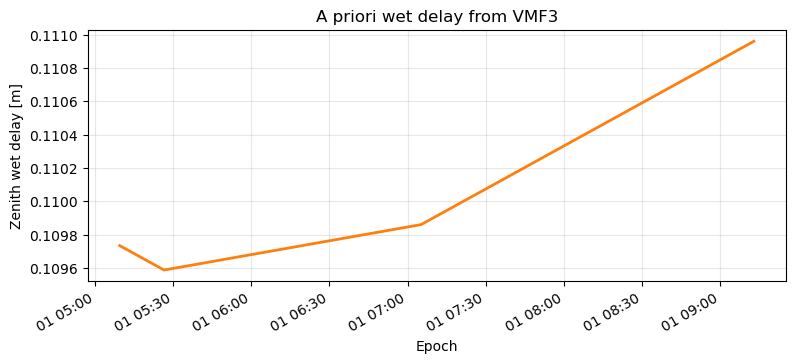

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.7))
ax.plot(times, vmf_zwd, color='tab:orange', lw=2)
ax.set(xlabel='Epoch', ylabel='Zenith wet delay [m]', title='A priori wet delay from VMF3')
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

## 5. Mapping functions: from zenith to the slant path

A satellite is rarely directly above a beacon. The path through the atmosphere increases as the satellite approaches the horizon. VMF3 uses hydrostatic and wet mapping coefficients ($a_h$, $a_w$) to compute two distinct factors:

$$
T(e) = ZHD\,m_h(e) + ZWD\,m_w(e).
$$

The mapping functions depend on **elevation angle in radians** in the `SiteVmf3` API. Both are dimensionless. Their increase at low elevation explains why a small zenith error can become a much larger slant-path error.

To show *both* components, the following plot evaluates a range of elevation angles at a single epoch.

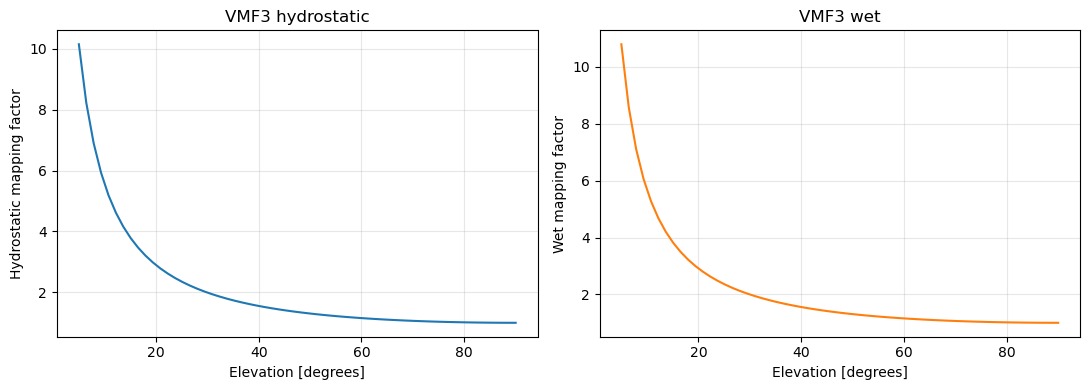

In [7]:
reference_epoch = times[len(times) // 2]
angles_deg = np.linspace(5, 90, 60)
m_h, m_w = [], []
for angle_deg in angles_deg:
    result = vmf.vmf3(SITE, latitude, longitude, np.deg2rad(angle_deg), reference_epoch)
    m_h.append(result['mfh'])
    m_w.append(result['mfw'])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(angles_deg, m_h)
axes[0].set(xlabel='Elevation [degrees]', ylabel='Hydrostatic mapping factor', title='VMF3 hydrostatic')
axes[1].plot(angles_deg, m_w, color='tab:orange')
axes[1].set(xlabel='Elevation [degrees]', ylabel='Wet mapping factor', title='VMF3 wet')
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

assert np.isclose(m_h[-1], 1.0, atol=1e-6)
assert np.isclose(m_w[-1], 1.0, atol=1e-6)

## 6. Slant delay during a DORIS pass

For each observation epoch, the actual line-of-sight elevation determines how the zenith dry and wet delays are mapped. `vmf.tropo_delay()` returns the **total slant path delay in metres**.

In *real mode*, elevations come from the DIOB station position and the interpolated Sentinel-6A SP3 position. This is only an approximate geometric illustration: a complete DORIS model also accounts for precise signal transmission/reception times and the relevant reference frames.

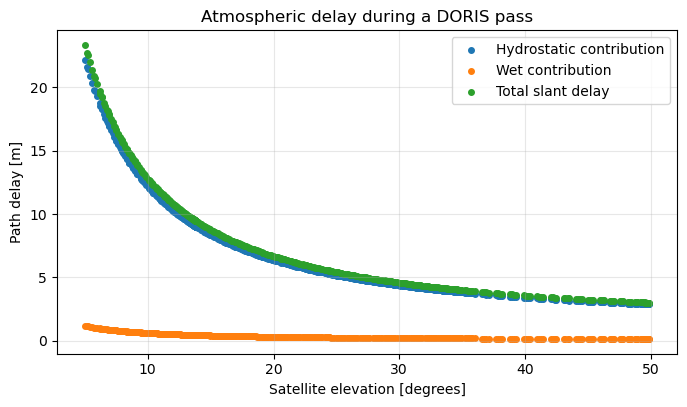

Near pass centre: elevation=32.2°; ZHD=2.195 m, ZWD=0.110 m; slant delay=4.313 m


In [8]:
# Compute the two slant contributions separately so students can see them.
slant_h = np.array([v['zhd'] * v['mfh'] for v in vmf_info])
slant_w = np.array([v['zwd'] * v['mfw'] for v in vmf_info])
slant_total = slant_h + slant_w

# Compare the explicit model equation with the convenience method.
check_delays = np.array([
    vmf.tropo_delay(SITE, latitude, longitude, float(el), t)
    for t, el in zip(times, elevations_rad)
])
assert np.allclose(slant_total, check_delays, rtol=0, atol=1e-10)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(np.degrees(elevations_rad), slant_h, s=16, label='Hydrostatic contribution')
ax.scatter(np.degrees(elevations_rad), slant_w, s=16, label='Wet contribution')
ax.scatter(np.degrees(elevations_rad), slant_total, s=16, label='Total slant delay')
ax.set(xlabel='Satellite elevation [degrees]', ylabel='Path delay [m]',
       title='Atmospheric delay during a DORIS pass')
ax.grid(alpha=0.3)
ax.legend()
plt.show()

mid = len(times)//2
print(f'Near pass centre: elevation={np.degrees(elevations_rad[mid]):.1f}°; '
      f'ZHD={vmf_zhd[mid]:.3f} m, ZWD={vmf_zwd[mid]:.3f} m; '
      f'slant delay={slant_total[mid]:.3f} m')

## 7. Why a delay in **metres** becomes a Doppler correction in **m/s**

DORIS observes the change of signal phase over a *count interval* (commonly 10 s). In a simplified one-way range-equivalent model,

$$
\lambda\,\frac{\phi(t_2)-\phi(t_1)}{t_2-t_1}
\;\approx\;
\frac{\rho(t_2)-\rho(t_1)}{t_2-t_1}
+ \frac{T(t_2)-T(t_1)}{t_2-t_1}
+ \text{other terms}.
$$

Therefore, the neutral-atmosphere contribution to **range rate** is approximately

$$
\boxed{\dot T\ \approx\ \frac{T(t_2)-T(t_1)}{t_2-t_1}\quad[\mathrm{m/s}].}
$$

For a carrier of nominal frequency $f$, a corresponding **Doppler-frequency** contribution has magnitude $|\delta f|\simeq f|\dot T|/c$ in hertz; the sign depends on the phase/Doppler observable convention. Here we demonstrate the range-rate correction and its magnitude, **not** a full DORIS observation equation.

We difference only **consecutive** samples with $0 < \Delta t \le 20$ s, so a gap between satellite passes is never treated as a 10-second Doppler count interval.

Range-rate contribution: -0.14274 to +0.20416 m/s
Approximate 2 GHz carrier-frequency contribution (sign convention dependent): -1.3867 to +0.9695 Hz


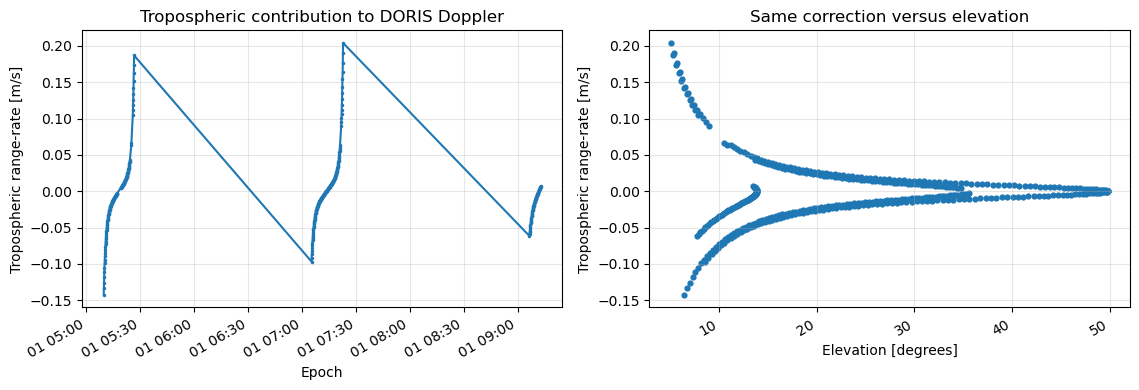

In [9]:
# Use integer-attosecond epochs for robust elapsed time, without rounding
# absolute timestamps to Unix floating-point seconds.
doppler_t = []
doppler_el_deg = []
tropo_rate_mps = []
for i in range(1, len(times)):
    dt_s = (to_attoseconds(times[i]) - to_attoseconds(times[i-1])) / 1e18
    if 0 < dt_s <= 20.0:
        rate = (slant_total[i] - slant_total[i-1]) / dt_s
        doppler_t.append(times[i])
        doppler_el_deg.append(np.degrees((elevations_rad[i] + elevations_rad[i-1]) / 2.0))
        tropo_rate_mps.append(rate)

tropo_rate_mps = np.asarray(tropo_rate_mps)
if not len(tropo_rate_mps):
    raise RuntimeError('No consecutive DORIS epochs within 20 s: cannot demonstrate Doppler differencing')

doppler_hz = -beacon_frequency_hz * tropo_rate_mps / C_LIGHT
print(f'Range-rate contribution: {np.min(tropo_rate_mps):+.5f} to '
      f'{np.max(tropo_rate_mps):+.5f} m/s')
print(f'Approximate 2 GHz carrier-frequency contribution (sign convention dependent): '
      f'{np.min(doppler_hz):+.4f} to {np.max(doppler_hz):+.4f} Hz')

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
axes[0].plot(doppler_t, tropo_rate_mps, marker='.', ms=3)
axes[0].set(xlabel='Epoch', ylabel='Tropospheric range-rate [m/s]',
            title='Tropospheric contribution to DORIS Doppler')
axes[1].scatter(doppler_el_deg, tropo_rate_mps, s=12)
axes[1].set(xlabel='Elevation [degrees]', ylabel='Tropospheric range-rate [m/s]',
            title='Same correction versus elevation')
for ax in axes:
    ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

### A small positioning intuition: what if ZWD is wrong by 2 cm?

Even if a wet-delay error is constant **in the zenith**, it is not constant along a moving satellite pass, because the *wet mapping function* changes. Consequently, it can leave a signature in the Doppler observable. This motivates estimating a residual $\Delta ZWD$ in a positioning adjustment.

In [10]:
# Illustrative constant 2 cm *zenith* wet-delay modeling error.
# Its slant contribution changes with elevation: delta_T = delta_ZWD * m_w.
delta_zwd_m = 0.02
m_w_pass = np.asarray([d['mfw'] for d in vmf_info])
wet_error_rate = []
for i in range(1, len(times)):
    dt_s = (to_attoseconds(times[i]) - to_attoseconds(times[i-1])) / 1e18
    if 0 < dt_s <= 20.0:
        wet_error_rate.append(delta_zwd_m * (m_w_pass[i] - m_w_pass[i-1]) / dt_s)

print(f'A fixed +2 cm ZWD error causes up to '
      f'{1000 * np.max(np.abs(wet_error_rate)):.3f} mm/s of Doppler range-rate error '
      'during this pass.')

A fixed +2 cm ZWD error causes up to 2.073 mm/s of Doppler range-rate error during this pass.


## 8. What to remember before positioning

- **Pressure-derived ZHD:** accurate surface pressure provides a practical hydrostatic model; check pressure units (hPa) and include latitude and height.
- **VMF3:** site-wise DORIS `*.vmf3_d` products provide model **ZHD, ZWD, $a_h, a_w$**, normally at discrete time steps. `SiteVmf3` interpolates those quantities in time and computes both mapping factors.
- **Path delay versus Doppler:** $T$ is in **metres**; $\Delta T/\Delta t$ is in **metres per second**. Never label a differenced delay as metres.
- **Positioning:** the model-derived wet delay is *a priori*. An actual solution may estimate a residual wet delay or tropospheric parameters; this notebook does not estimate them from observations.
- **Time systems and geometry:** RINEX, SP3, VMF3 and SINEX epochs must be reconciled. The geometric calculations here are illustrative and omit several terms of a complete DORIS model.
- **Low elevations:** mapping factors grow sharply, making an atmospheric modeling error more important; practical processing often uses an elevation cutoff.

**Questions for students:** Why is ZHD easier to predict than ZWD? Why do the hydrostatic and wet mapping factors differ? Why is the range-rate correction sometimes positive and sometimes negative during a pass?

### References

- [International DORIS Service — notebooks and DORIS basics](https://ids-doris.org/user-corner/section-content-usercorner.html?id=63&view=category)
- [International DORIS Service — RINEX/DORIS format](https://ids-doris.org/user-corner/about-doris-rinex-format.html)
- [TU Wien VMF Data Server — DORIS site-wise VMF3 products](https://vmf.geo.tuwien.ac.at/products.html)